# Homework 4 — Evaluación de modelos

Solución de `homework.md` usando `data/course_lead_scoring_2026.csv`.

In [1]:
import pandas as pd

## Data preparation

In [2]:
df = pd.read_csv("data/course_lead_scoring_2026.csv")

In [3]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
categorical = list(df.columns[df.dtypes == "str"])

In [5]:
df[categorical] = df[categorical].fillna("NA")

In [6]:
numerical = [
    "annual_income",
    "number_of_courses_viewed",
    "interaction_count",
    "lead_score",
]

In [7]:
df[numerical] = df[numerical].fillna(0)

In [8]:
df.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

## Split the data

In [9]:
from sklearn.model_selection import train_test_split

In [10]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

## Q1. ROC AUC feature importance

In [11]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [12]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [13]:
del df_train["converted"]
del df_val["converted"]
del df_test["converted"]

In [14]:
from sklearn.metrics import auc, roc_auc_score

In [15]:
for var in numerical:
    auc_score = roc_auc_score(y_train, df_train[var])
    print(f"Variable: {var} -> AUC Final: {auc_score:.4f}")

Variable: annual_income -> AUC Final: 0.6082
Variable: number_of_courses_viewed -> AUC Final: 0.7230
Variable: interaction_count -> AUC Final: 0.7649
Variable: lead_score -> AUC Final: 0.7882


**Respuesta:** `lead_score` (AUC ≈ 0.7882, la más alta entre las 4 variables)

## Q2. Training the model

In [16]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient="records")
X_train = dv.fit_transform(train_dict)

val_dict = df_val[categorical + numerical].to_dict(orient="records")
X_val = dv.transform(val_dict)

In [17]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [18]:
y_pred = model.predict_proba(X_val)[:, 1]

In [19]:
round(roc_auc_score(y_val, y_pred), 3) 

0.732

**Respuesta:** 0.732

## Q3. Precision and Recall

In [20]:
import numpy as np
from sklearn.metrics import precision_score, recall_score

In [21]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_predict = (y_pred >= t).astype(int)

    p = precision_score(y_val, actual_predict, zero_division=0)
    r = recall_score(y_val, actual_predict, zero_division=0)
    if p == 0 and r == 0:
        continue

    diff = abs(p - r)
    scores.append((t, p, r, diff))
    columns = ["threshold", "p", "r", "diff"]
    df_scores = pd.DataFrame(scores, columns=columns)

In [22]:
import matplotlib.pyplot as plt

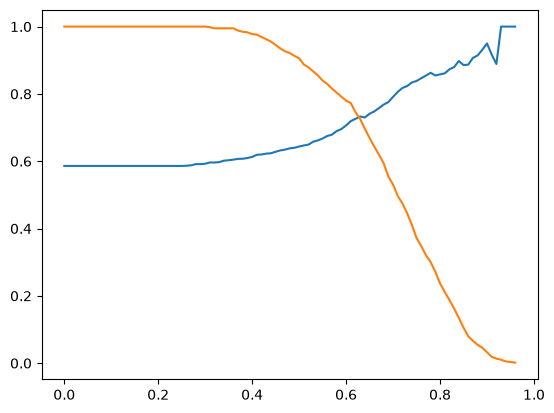

In [23]:
plt.plot(df_scores.threshold, df_scores.p, label="p")
plt.plot(df_scores.threshold, df_scores.r, label="r")

plt.show()

In [24]:
scores.sort(key=lambda x: x[3])

In [25]:
best_t, best_p, best_r, min_diff = scores[0]

In [26]:
print(f"El punto de intersección es en el umbral: {best_t:.2f}")
print(f"Precisión: {best_p:.4f}, Recall: {best_r:.4f} (Diferencia: {min_diff:.4f})")

El punto de intersección es en el umbral: 0.63
Precisión: 0.7328, Recall: 0.7253 (Diferencia: 0.0075)


**Respuesta:** 0.63

## Q4. F1 score

In [27]:
f1_scores = []

for t in thresholds:
    actual_predict = (y_pred >= t).astype(int)

    p = precision_score(y_val, actual_predict, zero_division=0)
    r = recall_score(y_val, actual_predict, zero_division=0)
    if (p + r) == 0:
        f1 = 0.0
    else:
        f1 = 2 * p * r / (p + r)
    f1_scores.append((t, f1))
    columns = ["threshold", "f1"]
    df_scores = pd.DataFrame(f1_scores, columns=columns)

In [28]:
max(f1_scores,key=lambda x: x[1])

(np.float64(0.41000000000000003), 0.7576158940397352)

**Respuesta:** 0.41

## Q5. 5-Fold CV

In [29]:
from sklearn.model_selection import KFold

In [30]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [31]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient="records")

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

In [32]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient="records")

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [33]:
auc_scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]

    y_train_fold = df_train_fold.converted.values
    y_val_fold = df_val_fold.converted.values

    dv, model = train(df_train_fold, y_train_fold, C=1.0)
    y_pred_fold = predict(df_val_fold, dv, model)

    auc_score = roc_auc_score(y_val_fold, y_pred_fold)
    auc_scores.append(auc_score)

auc_mean = np.mean(auc_scores)
auc_std = np.std(auc_scores)

print(f"Puntajes AUC por fold: {[round(score, 3) for score in auc_scores]}")
print(f"Media del AUC: {auc_mean:.3f}")
print(f"Desviación Estándar del AUC: {auc_std:.3f}")

Puntajes AUC por fold: [0.731, 0.73, 0.736, 0.741, 0.721]
Media del AUC: 0.732
Desviación Estándar del AUC: 0.007


**Respuesta:** std ≈ 0.007

## Q6. Hyperparameter Tuning

In [34]:
from tqdm.auto import tqdm

n_splits = 5

for C in tqdm([0.000001, 0.001, 1]):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)

    auc_scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]

        y_train_fold = df_train_fold.converted.values
        y_val_fold = df_val_fold.converted.values

        dv, model = train(df_train_fold, y_train_fold, C=C)
        y_pred_fold = predict(df_val_fold, dv, model)

        auc_score = roc_auc_score(y_val_fold, y_pred_fold)
        auc_scores.append(auc_score)

    print("C=%s %.3f +- %.3f" % (C, np.mean(auc_scores), np.std(auc_scores)))

C:\Users\Acer123\Personal\Aprender\python\data-analysis\ds\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  0%|          | 0/3 [00:00<?, ?it/s]

 33%|███▎      | 1/3 [00:00<00:00,  3.56it/s]

C=1e-06 0.617 +- 0.019


 67%|██████▋   | 2/3 [00:00<00:00,  3.59it/s]

C=0.001 0.749 +- 0.010


100%|██████████| 3/3 [00:00<00:00,  3.68it/s]

100%|██████████| 3/3 [00:00<00:00,  3.65it/s]

C=1 0.732 +- 0.007


**Respuesta:** C = 0.001 (AUC media ≈ 0.749, la más alta)